In [1]:
# Step 1: Importing Libraries and Loading the Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('adult_dataset.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [5]:
# Step 2: Data Preprocessing

# Replace '?' with NaN
df.replace('?', np.nan, inplace=True)

# 1. Handle missing values
# For categorical columns, fill with mode
cat_cols = ['workclass', 'occupation', 'native-country']
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# For numerical columns, fill with median
num_cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)

# 2. Drop income column before clustering
df_cluster = df.drop(columns=['income'])

# 3. Encode categorical variables using Label Encoder (simple student approach)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df_cluster.select_dtypes(include=['object']).columns:
    df_cluster[col] = le.fit_transform(df_cluster[col])

# 4. Outlier treatment using IQR method
for col in num_cols:
    Q1 = df_cluster[col].quantile(0.25)
    Q3 = df_cluster[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_cluster[col] = np.clip(df_cluster[col], lower, upper)

# 5. Scale numerical features using StandardScaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_cluster)

# Convert back to dataframe
df_scaled = pd.DataFrame(X_scaled, columns=df_cluster.columns)
print("Preprocessing finished! Null values left:", df_scaled.isnull().sum().sum())
df_scaled.head()

Preprocessing finished! Null values left: 0


/tmp/ipykernel_968/994030164.py:10: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)
/tmp/ipykernel_968/994030164.py:15: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try usi

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.035311,2.689753,-1.146097,-0.332542,1.171374,0.916138,-1.607439,-0.276685,0.392384,0.70422,0.0,0.0,-0.187236,0.253224
1,0.864184,1.763894,-1.085307,-0.332542,1.171374,-0.410397,-0.841761,-0.900852,0.392384,0.70422,0.0,0.0,-1.430298,0.253224
2,-0.040041,-0.087824,0.302906,0.183660,-0.456714,-1.736932,-0.331310,-0.276685,0.392384,0.70422,0.0,0.0,-0.187236,0.253224
3,1.090241,-0.087824,0.503005,-2.397350,-1.270758,-0.410397,-0.331310,-0.900852,-1.971746,0.70422,0.0,0.0,-0.187236,0.253224
4,-0.793562,-0.087824,1.590706,-0.332542,1.171374,-0.410397,0.689594,2.219984,-1.971746,-1.42001,0.0,0.0,-0.187236,-5.512975


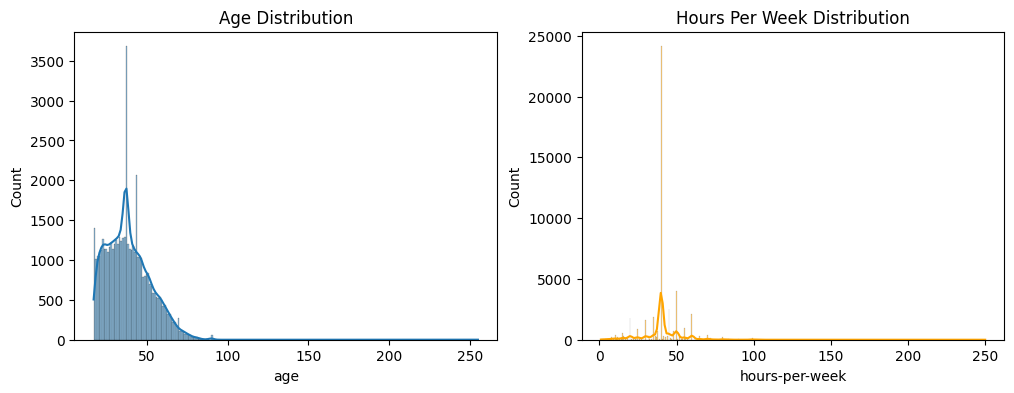

Capital Gain Skewness: 11.894658996587946
Capital Loss Skewness: 4.569808857738485


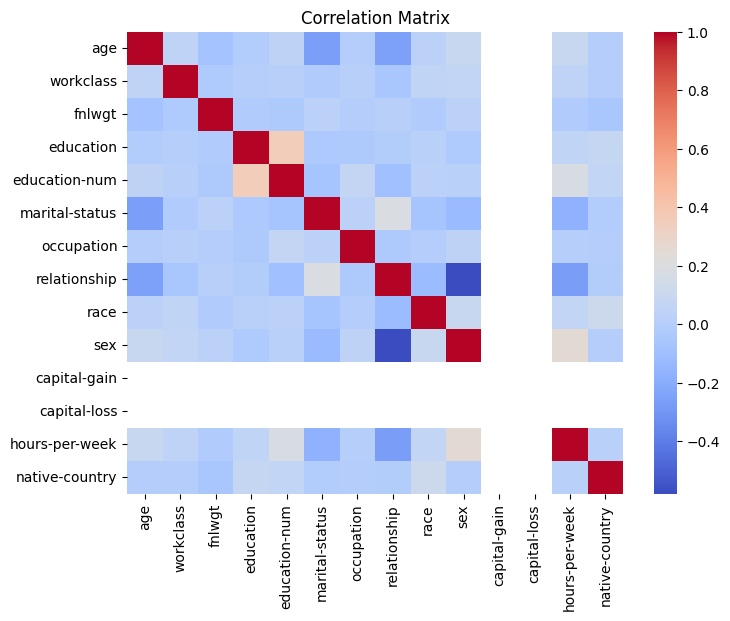

In [7]:
# Step 3: Exploratory Data Analysis (EDA)

# Plotting distributions
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(df['age'], kde=True)
plt.title('Age Distribution')

plt.subplot(1, 2, 2)
sns.histplot(df['hours-per-week'], kde=True, color='orange')
plt.title('Hours Per Week Distribution')
plt.show()

# Check skewness
print("Capital Gain Skewness:", df['capital-gain'].skew())
print("Capital Loss Skewness:", df['capital-loss'].skew())

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df_cluster.corr(), annot=False, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

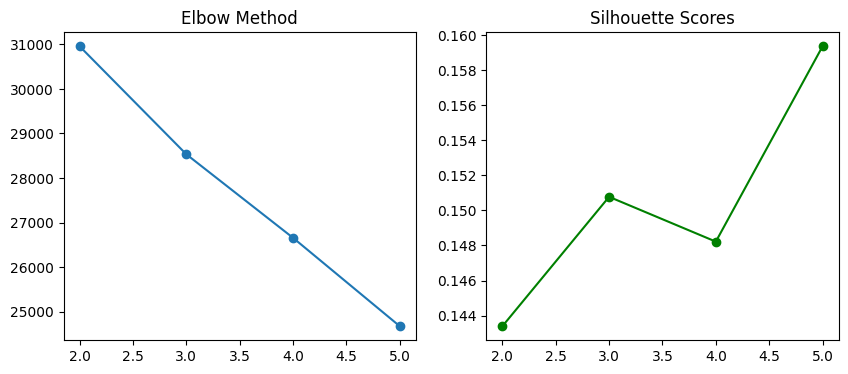

In [10]:
# Step 4: Clustering

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Using a smaller sample of data to make it run faster
df_sample = df_scaled.sample(n=3000, random_state=42)

# Elbow method
inertia = []
sil_scores = []
K = range(2, 6)

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(df_sample)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(df_sample, labels))

# Plot Elbow and Silhouette
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(K, inertia, marker='o')
plt.title('Elbow Method')

plt.subplot(1, 2, 2)
plt.plot(K, sil_scores, marker='o', color='green')
plt.title('Silhouette Scores')
plt.show()

# Fit final KMeans with K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(df_sample)

# Fit Agglomerative Clustering
agg = AgglomerativeClustering(n_clusters=3)
agg_labels = agg.fit_predict(df_sample)


Explained Variance Ratio: [0.16708863 0.11312998]
First 10 rows of PC1 and PC2:
        PC1       PC2  KMeans  Agglomerative
0  0.904174 -1.046144       2              1
1  2.902707 -1.560303       0              2
2  1.115393 -0.391193       2              0
3  2.419127  1.006077       2              0
4  0.871193 -0.330117       2              0
5 -0.612958 -0.184843       1              0
6 -0.894361 -0.483495       1              1
7 -0.094170 -3.243520       0              2
8 -0.149302  0.209126       1              1
9  2.218106  0.487791       2              0
Explained Variance Ratio: [0.16708863 0.11312998]


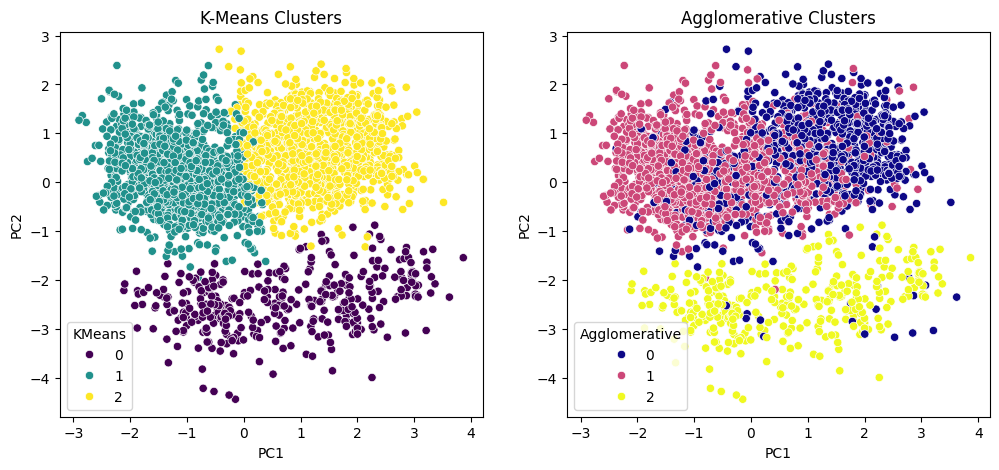

In [15]:
# Step 5: Dimensionality Reduction using PCA

from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_data = pca.fit_transform(df_sample)

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['KMeans'] = kmeans_labels
pca_df['Agglomerative'] = agg_labels

print("First 10 rows of PC1 and PC2:")
print(pca_df.head(10))


# Scatter plot comparison
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='PC1', y='PC2', hue='KMeans', data=pca_df, palette='viridis')
plt.title('K-Means Clusters')

plt.subplot(1, 2, 2)
sns.scatterplot(x='PC1', y='PC2', hue='Agglomerative', data=pca_df, palette='plasma')
plt.title('Agglomerative Clusters')
plt.show()

PC1: 0.16708863 (approx. 16.71%)

PC2: 0.11312998 (approx. 11.31%)

Total Variance : 28.01% (16.71\% + 11.31\%)
